In [1]:
import os
import glob
import shutil
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
from PIL import Image
import cv2 as cv
import matplotlib.pyplot as plt

In [2]:
def extract_characters_from_image(image): #results in /demo/results
    img = cv.imread(image)
    if img is None:
        print(f"Error: Could not read image {image}")
        return

    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    #cv.imshow('gray image', gray)

    # Optional: improve contrast
    gray = cv.equalizeHist(gray)

    # Threshold (adaptive) – keep text white, background black
    thresh = cv.adaptiveThreshold(
        gray, 255,
        cv.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv.THRESH_BINARY_INV,
        35, 10
    )
    cv.imshow('thresholded image', thresh)

    # Morphology to clean noise (larger kernel)
    kernel = cv.getStructuringElement(cv.MORPH_RECT, (3,3)) #bigger numbers add background blur
    morph = cv.morphologyEx(thresh, cv.MORPH_OPEN, kernel, iterations=1)  # remove specks
    morph = cv.morphologyEx(morph, cv.MORPH_CLOSE, kernel, iterations=1)  # connect strokes
    cv.imshow('morphological image', morph)

    # Use connected components instead of contours
    num_labels, labels, stats, centroids = cv.connectedComponentsWithStats(morph, connectivity=8)

    # Visualization
    vis = cv.cvtColor(morph, cv.COLOR_GRAY2BGR)

    os.makedirs("./demo/results", exist_ok=True)

    for i in range(1, num_labels):  # skip background
        x, y, w, h, area = stats[i]

        # Filter blobs (remove tiny specks and very large areas)
        if area < 50 or w*h > 0.15*img.shape[0]*img.shape[1]:
            continue

        pad_top = 15   # extend upward
        pad_bottom = 5 # extend downward a bit

        # ensure we don't go out of bounds
        y_start = max(y - pad_top, 0)
        y_end = min(y + h + pad_bottom, morph.shape[0])

        char_img = morph[y_start:y_end, x:x+w]
        # Draw boxes for visualization
        cv.rectangle(vis, (x, y_start), (x+w, y_end), (0, 255, 0), 1)
        cv.putText(vis, f'{i}', (x, max(y_start - 5, 0)), 
           cv.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1, cv.LINE_AA)
        testNum = image[-5]
        cv.imwrite(f'demo/results/{testNum}_char_{i}.png', char_img)
        #cv.imwrite(f'./results/char_{i}.png', char_img)
        # Draw boxes for visualization
        #cv.rectangle(vis, (x, y), (x+w, y+h + 10), (0, 255, 0), 1)

    cv.imshow("characters", vis)

    cv.waitKey(0)
    cv.destroyAllWindows()



def clear_folder(folder_path: str):
    """
    Clears all contents of the given folder but keeps the folder itself.
    If the folder does not exist, it will be created.
    """
    if not os.path.exists(folder_path):
        os.makedirs(folder_path)
        print(f"Created folder: {folder_path}")
        return

    for filename in os.listdir(folder_path):
        file_path = os.path.join(folder_path, filename)
        try:
            if os.path.isfile(file_path) or os.path.islink(file_path):
                os.remove(file_path)      # delete file or symlink
            elif os.path.isdir(file_path):
                shutil.rmtree(file_path)  # delete folder
        except Exception as e:
            print(f"Failed to delete {file_path}. Reason: {e}")

    print(f"Cleared contents of: {folder_path}")
        

In [ ]:
#extract_characters_from_image('./data/tests/test2.png')
for i in range(4,7):
    filepath = f'./data/tests/test{i}.png'
    chars = extract_characters_from_image(filepath)
    # extract_characters_from_image(f'./data/tests/test{i}.png') 11:52

In [ ]:
clear_folder('./demo/results')

In [ ]:
def run_human_trainer():
    """
    Display each image in results_training and wait for user to press a key.
    Moves the image into results_paired_human/upper/<char>/ or results_paired_human/lower/<char>/:
    - Uppercase letters go to upper/<letter>
    - Lowercase letters go to lower/<letter>
    - Letters in 'wouypskzxcv' always go to lower/<letter.lower()>
    """
    import cv2 as cv
    import os
    import shutil

    src_folder = "./demo/results"
    dst_folder = "./demo/results_paired_human"
    merge_letters = "wouypskzxcv"

    # Create main upper/lower folders
    upper_folder = os.path.join(dst_folder, "upper")
    lower_folder = os.path.join(dst_folder, "lower")
    os.makedirs(upper_folder, exist_ok=True)
    os.makedirs(lower_folder, exist_ok=True)

    for filename in os.listdir(src_folder):
        if filename.lower().endswith((".png", ".jpg", ".jpeg")):
            img_path = os.path.join(src_folder, filename)
            print(f"Processing: {img_path}")

            img = cv.imread(img_path)
            if img is None:
                print(f"Could not open {img_path}")
                continue

            # Show the image
            cv.imshow("Label this character (press key)", img)
            key = cv.waitKey(0)
            cv.destroyAllWindows()

            if key == 27:  # ESC = quit
                print("Exiting labeling.")
                break
            elif key == 32:  # SPACE = skip
                print("Skipped.")
                continue
            else:
                char = chr(key)
                print(f"Labeled as: {char}")

                # Determine if the file goes to upper or lower
                if char.lower() in merge_letters or char.islower():
                    parent_folder = lower_folder
                    char_subfolder = char.lower()
                else:
                    parent_folder = upper_folder
                    char_subfolder = char

                # Create the character subfolder if it doesn't exist
                char_folder = os.path.join(parent_folder, char_subfolder)
                os.makedirs(char_folder, exist_ok=True)

                # Append key to filename to avoid overwriting
                base, ext = os.path.splitext(filename)
                new_filename = f"{base}{char}{ext}"
                dst_path = os.path.join(char_folder, new_filename)

                shutil.move(img_path, dst_path)
                print(f"Moved and renamed to {dst_path}")


In [ ]:
run_human_trainer()

In [ ]:
clear_folder('./demo/results_paired_human')

In [6]:
from tensorflow.keras.models import load_model
model_2 = load_model("small_dataset.keras")
model_10 = load_model("10_epochs.keras")
model_13 = load_model("13_epochs.keras")

In [4]:
emnist_labels = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"  #0-10, A-Z, a-z
def predict_char(model, image_path: str, show_image: bool = True):
    """
    Given a trained model and a path to a character image,
    preprocesses the image, optionally shows it, and returns the predicted character.
    Rotates the image 90 degrees before prediction.
    """
    # Load and preprocess image
    img = Image.open(image_path).convert("L")  # grayscale
    img = img.resize((28, 28))                 # resize to 28x28

    # Rotate image 90 degrees counterclockwise
    #img = img.rotate(90, expand=True)

    img = np.array(img)

    # Normalize to 0-1
    img_norm = img / 255.0

    # Optionally show the preprocessed image
    if show_image:
        plt.imshow(img_norm, cmap='gray')
        plt.title("Preprocessed Image")
        plt.axis('off')
        plt.show()

    # Add batch and channel dimension: (1, 28, 28, 1)
    img_input = np.expand_dims(img_norm, axis=(0, -1))

    # Predict
    preds = model.predict(img_input)
    class_index = np.argmax(preds)
    predicted_char = emnist_labels[class_index]

    # Confidence/probability of the predicted class
    confidence = preds[0][class_index]

    print(f"Predicted character: {predicted_char} (Confidence: {confidence:.2f})")

    return predicted_char, confidence

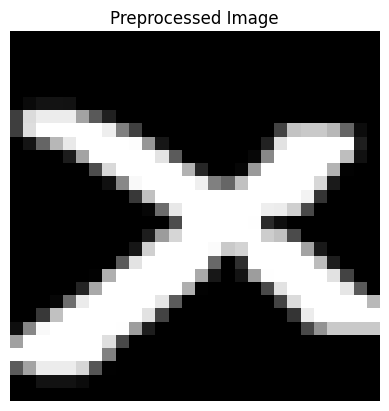

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 587ms/step
Predicted character: X (Confidence: 0.60)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 377ms/step
Predicted character: X (Confidence: 0.65)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step
Predicted character: X (Confidence: 0.99)


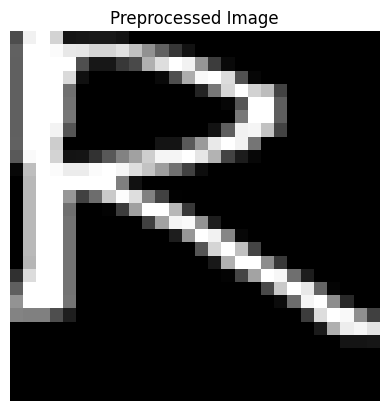

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
Predicted character: K (Confidence: 0.81)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
Predicted character: K (Confidence: 0.63)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
Predicted character: R (Confidence: 0.81)


('R', np.float32(0.8105674))

In [7]:
#X
predict_char(model_13, './data/model-citizen/char_X.png', show_image=True)
predict_char(model_10, './data/model-citizen/char_X.png', show_image=False)
predict_char(model_2, './data/model-citizen/char_X.png', show_image=False)
#R
predict_char(model_13, './data/model-citizen/char_R.png', show_image=True)
predict_char(model_10, './data/model-citizen/char_R.png', show_image=False)
predict_char(model_2, './data/model-citizen/char_R.png', show_image=False)


In [ ]:
extract_characters_from_image('./data/tests/ThankYou.png')

In [ ]:
#Training a 200mb model

In [ ]:
# super_guesser.py
import os
import json
import tensorflow as tf
import tensorflow_datasets as tfds

# ---------------------------
# Repro & config
# ---------------------------
SEED = 42
tf.keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

# 62-class label ordering for EMNIST/byclass
EMNIST_LABELS = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"

NUM_CLASSES = len(EMNIST_LABELS)
BATCH_SIZE = 256
EPOCHS = 30

MODEL_OUT_KERAS = "super_guesser.keras"    # single-file Keras format
SAVEDMODEL_DIR  = "super_guesser_saved"    # optional SavedModel dir
LABELS_JSON     = "labels.json"            # char mapping for inference

# ---------------------------
# Data: load & preprocessing
# ---------------------------
def normalize_and_fix_orientation(image, label):
    # EMNIST images are 28x28, uint8. Normalize to [0,1].
    image = tf.cast(image, tf.float32) / 255.0
    # Match the rotation you used at inference (rotate 90° CCW)
    image = tf.image.rot90(image, k=1)
    # Add channel dimension
    image = tf.expand_dims(image, axis=-1)  # (28,28,1)
    return image, label

def prepare_dataset(ds, training=False):
    ds = ds.map(normalize_and_fix_orientation, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.shuffle(20_000, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

print("Loading EMNIST/byclass…")
ds_train = tfds.load('emnist/byclass', split='train', as_supervised=True)
ds_test  = tfds.load('emnist/byclass', split='test',  as_supervised=True)

# Optional: carve a validation split out of train
TRAIN_SPLIT = 0.9
train_count = ds_train.cardinality().numpy()
val_take    = int((1.0 - TRAIN_SPLIT) * train_count)

ds_val   = ds_train.take(val_take)
ds_train = ds_train.skip(val_take)

ds_train = prepare_dataset(ds_train, training=True)
ds_val   = prepare_dataset(ds_val, training=False)
ds_test  = prepare_dataset(ds_test, training=False)

# ---------------------------
# Data augmentation (on-GPU)
# ---------------------------
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.10, fill_mode="nearest"),
    tf.keras.layers.RandomTranslation(0.10, 0.10, fill_mode="nearest"),
    tf.keras.layers.RandomZoom(0.10),
], name="augmentation")

# ---------------------------
# Model: strong CNN backbone
# ---------------------------
def build_model(input_shape=(28,28,1), num_classes=NUM_CLASSES):
    inputs = tf.keras.Input(shape=input_shape)

    x = data_augmentation(inputs)

    # Block 1
    x = tf.keras.layers.Conv2D(32, (3,3), padding='same', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.Conv2D(32, (3,3), padding='same', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.MaxPooling2D()(x)
    x = tf.keras.layers.Dropout(0.25)(x)

    # Block 2
    x = tf.keras.layers.Conv2D(64, (3,3), padding='same', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.Conv2D(64, (3,3), padding='same', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.MaxPooling2D()(x)
    x = tf.keras.layers.Dropout(0.25)(x)

    # Block 3
    x = tf.keras.layers.Conv2D(128, (3,3), padding='same', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.Conv2D(128, (3,3), padding='same', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.MaxPooling2D()(x)
    x = tf.keras.layers.Dropout(0.30)(x)

    # Head
    x = tf.keras.layers.Flatten()(x)
    x = tf.keras.layers.Dense(256, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax')(x)

    model = tf.keras.Model(inputs, outputs, name="super_guesser")
    return model

model = build_model()
model.summary()

# ---------------------------
# Compile
# ---------------------------
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(
    optimizer=optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top3_acc')
    ],
)

# ---------------------------
# Callbacks
# ---------------------------
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=5,
        mode='max',
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=MODEL_OUT_KERAS,
        monitor='val_accuracy',
        mode='max',
        save_best_only=True,
        save_weights_only=False
    )
]

# ---------------------------
# Train
# ---------------------------
history = model.fit(
    ds_train,
    validation_data=ds_val,
    epochs=EPOCHS,
    callbacks=callbacks
)

# ---------------------------
# Evaluate
# ---------------------------
print("\nEvaluating on test set…")
test_metrics = model.evaluate(ds_test, return_dict=True)
for k, v in test_metrics.items():
    print(f"{k}: {v:.4f}")

# ---------------------------
# Save model + labels
# ---------------------------
# Save again (best weights are already in the checkpoint; this ensures both formats)
print(f"\nSaving Keras model -> {MODEL_OUT_KERAS}")
model.save(MODEL_OUT_KERAS)

print(f"Saving SavedModel -> {SAVEDMODEL_DIR}")
# overwrite if exists
if os.path.exists(SAVEDMODEL_DIR):
    import shutil; shutil.rmtree(SAVEDMODEL_DIR)
model.save(SAVEDMODEL_DIR, save_format="tf")

print(f"Writing labels mapping -> {LABELS_JSON}")
with open(LABELS_JSON, "w") as f:
    json.dump({"indices_to_chars": list(EMNIST_LABELS)}, f, ensure_ascii=False, indent=2)

print("\nDone. Files written:")
print(f" - {MODEL_OUT_KERAS}")
print(f" - {SAVEDMODEL_DIR}/")
print(f" - {LABELS_JSON}")


In [ ]:
extract_characters_from_image('./data/tests/ThankYou.png')

In [ ]:
'''



'''